# Exploratory Data Analysis: Berkeley Lab Queue Data 2025

## Purpose
This notebook evaluates every worksheet in the Berkeley Lab workbook and performs project-level EDA on the complete queue dataset. The modeling question is:

> **For a newly queued California solar project, what is the probability that it eventually becomes operational before it withdraws?**

This is more precise than “accepted versus rejected.” `withdrawn` is not necessarily a formal rejection, and `active` is an unresolved, right-censored status rather than a successful outcome.

## 1. Imports and reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("../Data_ML_SQL/Berkeley_LabQueue_Data_2025.xlsx")
assert DATA_PATH.exists(), f"Missing data file: {DATA_PATH}"
print("Imports and data path ready.")

Imports and data path ready.


## 2. Workbook inventory: load every sheet

All 41 sheets are loaded. The project-level source is `03. Complete Queue Data`; documentation and summary sheets are retained for auditing and reconciliation rather than concatenated as project records.

In [2]:
excel_file = pd.ExcelFile(DATA_PATH)
all_sheets_raw = pd.read_excel(DATA_PATH, sheet_name=None, header=None)

def classify_sheet(name):
    if name == "03. Complete Queue Data":
        return "project-level data"
    if name in {"Introduction", "Contents", "00. Background + Methods",
                "01. Balancing Areas", "04. Data Codebook"}:
        return "documentation"
    return "published summary"

sheet_inventory = pd.DataFrame({
    "sheet": excel_file.sheet_names,
    "rows_raw": [all_sheets_raw[name].shape[0] for name in excel_file.sheet_names],
    "columns_raw": [all_sheets_raw[name].shape[1] for name in excel_file.sheet_names],
    "role": [classify_sheet(name) for name in excel_file.sheet_names],
})

print(f"Loaded {len(all_sheets_raw)} of {len(excel_file.sheet_names)} available sheets.")
display(sheet_inventory)

Loaded 43 of 43 available sheets.


,sheet,rows_raw,columns_raw,role
0,Introduction,39,6,documentation
1,Contents,42,3,documentation
2,00. Background + Methods,22,6,documentation
3,01. Balancing Areas,20,5,documentation
4,02. Data Sample by Region,19,7,published summary
5,03. Complete Queue Data,38203,30,project-level data
6,04. Data Codebook,32,3,documentation
7,05. Annual Requests,49,3,published summary
8,06. Capacity Change YoY,36,2,published summary
9,07. Active Capacity by Year,47,3,published summary


## 3. Correct project-data and codebook loading

In [3]:
# Row 0 is a navigation row; row 1 contains the real project-data header.
df = pd.read_excel(DATA_PATH, sheet_name="03. Complete Queue Data", header=1)
codebook = pd.read_excel(DATA_PATH, sheet_name="04. Data Codebook", header=1)

# Defensive cleanup.
df.columns = df.columns.astype(str).str.strip()
df = df[df["q_status"].isin(["active", "operational", "withdrawn",
                             "suspended", "unknown"])].copy()

date_cols = ["q_date", "prop_date", "on_date", "wd_date", "ia_date"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

mw_cols = ["mw_1", "mw_2", "mw_3"]
for col in mw_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["total_mw"] = df[mw_cols].fillna(0).sum(axis=1)
df["is_hybrid"] = df[["type_2", "type_3"]].notna().any(axis=1)
df["queue_year"] = df["q_date"].dt.year
df["resolved_outcome"] = df["q_status"].where(
    df["q_status"].isin(["operational", "withdrawn"])
)

print(f"Project rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
display(codebook.head(30))

Project rows: 38,201
Columns: 34


,Field Name,Description,Notes
0,q_id,queue position / ID number,"Combine with ""entity"" to form a unique identif..."
1,q_status,current queue status,"One of: active, withdrawn, suspended, or opera..."
2,q_date,interconnection request date (date project ent...,NaN
3,prop_date,proposed online date from interconnection appl...,Proposed date can be revised during the interc...
4,on_date,date project became operational (if applicable),NaN
5,wd_date,date project withdrawn from queue (if applicable),NaN
6,ia_date,date of signed interconnection agreement (if a...,NaN
7,IA_phase_raw,non-standardized interconnection study phase /...,NaN
8,IA_phase_clean,standardized interconnection study phase / status,"We impute ""IA Executed"" if q_status is ""operat..."
9,county,county where project is located,"For requests spanning multiple counties, only ..."


## 4. Data quality: schema, keys, missingness, and consistency

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)

compound_dup = df.duplicated(["entity", "q_id"], keep=False)
exact_dup = df.duplicated(keep=False)
negative_mw = (df[mw_cols] < 0).sum()

print(f"Exact duplicated rows: {exact_dup.sum():,}")
print(f"Rows in duplicated (entity, q_id) groups: {compound_dup.sum():,}")
print("Negative MW values (review rather than silently discard):")
display(negative_mw.to_frame("count"))
display(quality)

Exact duplicated rows: 0
Rows in duplicated (entity, q_id) groups: 270
Negative MW values (review rather than silently discard):


,count
mw_1,16
mw_2,0
mw_3,0


,dtype,non_null,missing,missing_pct,unique
mw_3,float64,45,38156,99.88,25
type_3,str,110,38091,99.71,4
mw_2,float64,1096,37105,97.13,431
on_date,datetime64[us],3709,34492,90.29,1891
ia_date,datetime64[us],4833,33368,87.35,2741
type_2,str,5057,33144,86.76,10
developer,str,8487,29714,77.78,4518
cluster,object,12395,25806,67.55,644
project_name,object,13088,25113,65.74,11555
wd_date,datetime64[us],15623,22578,59.10,4119


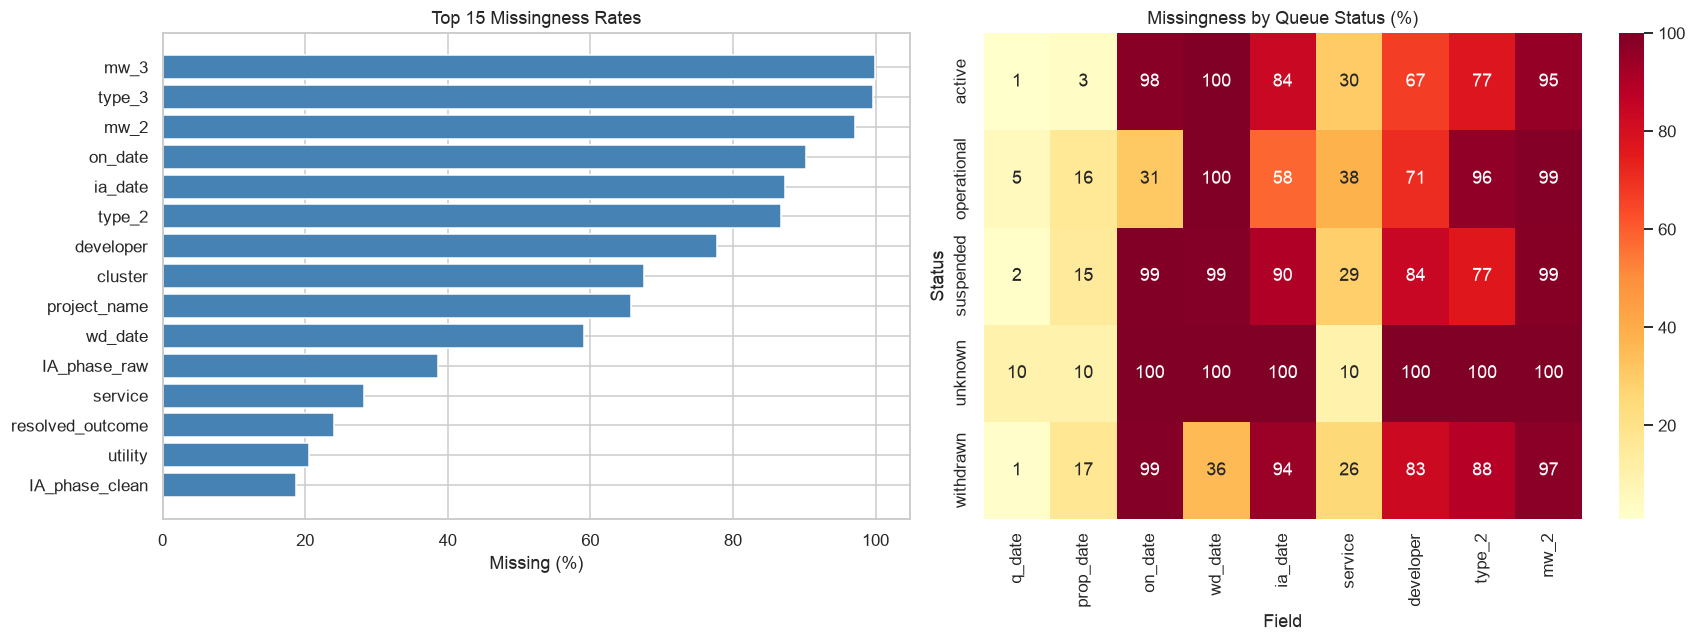

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_missing = quality.head(15).sort_values("missing_pct")
axes[0].barh(top_missing.index, top_missing["missing_pct"], color="steelblue")
axes[0].set_title("Top 15 Missingness Rates")
axes[0].set_xlabel("Missing (%)")

missing_by_status = (
    df.groupby("q_status")[date_cols + ["service", "developer", "type_2", "mw_2"]]
      .apply(lambda x: x.isna().mean() * 100)
)
sns.heatmap(missing_by_status, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[1])
axes[1].set_title("Missingness by Queue Status (%)")
axes[1].set_xlabel("Field")
axes[1].set_ylabel("Status")

plt.tight_layout()
plt.show()

## 5. Target definition and censoring

- `operational`: terminal success — reached operation.
- `withdrawn`: terminal exit before operation, but not necessarily a formal rejection.
- `active`: unresolved/right-censored and excluded from ordinary binary-classifier labels.
- `suspended` and `unknown`: analyzed separately; too ambiguous or sparse for the binary target.

,count,pct_all
q_status,,
operational,4789,12.54
withdrawn,24221,63.40
active,8513,22.28
suspended,668,1.75
unknown,10,0.03


Resolved modeling cohort: 29,010
Operational share among resolved: 16.51%
Class ratio withdrawn:operational = 5.06:1


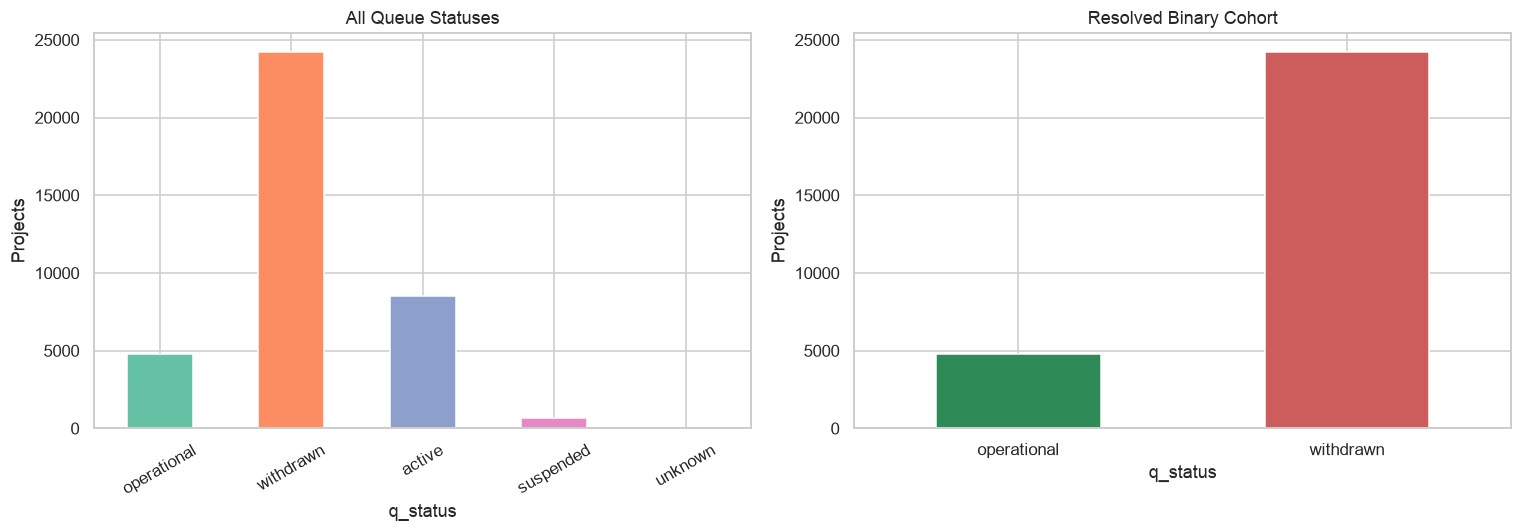

In [6]:
status_counts = df["q_status"].value_counts().reindex(
    ["operational", "withdrawn", "active", "suspended", "unknown"], fill_value=0
)
status_table = pd.DataFrame({
    "count": status_counts,
    "pct_all": (status_counts / len(df) * 100).round(2),
})

resolved = df[df["q_status"].isin(["operational", "withdrawn"])].copy()
resolved["reached_operation"] = (resolved["q_status"] == "operational").astype(int)
resolved_counts = resolved["q_status"].value_counts()

display(status_table)
print(f"Resolved modeling cohort: {len(resolved):,}")
print(f"Operational share among resolved: {resolved['reached_operation'].mean():.2%}")
print(f"Class ratio withdrawn:operational = "
      f"{resolved_counts.get('withdrawn', 0) / resolved_counts.get('operational', 1):.2f}:1")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
status_counts.plot.bar(ax=axes[0], color=sns.color_palette("Set2", len(status_counts)))
axes[0].set_title("All Queue Statuses")
axes[0].set_ylabel("Projects")
axes[0].tick_params(axis="x", rotation=30)

resolved_counts.reindex(["operational", "withdrawn"]).plot.bar(
    ax=axes[1], color=["seagreen", "indianred"]
)
axes[1].set_title("Resolved Binary Cohort")
axes[1].set_ylabel("Projects")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 6. Numerical distributions and probability-shape diagnostics

,feature,n,mean,median,std,skew,kurtosis,positive_n
0,mw_1,38201,179.056,100.0,256.650,10.345,486.821,38183
1,total_mw,38201,185.817,100.0,275.657,9.445,376.680,38185


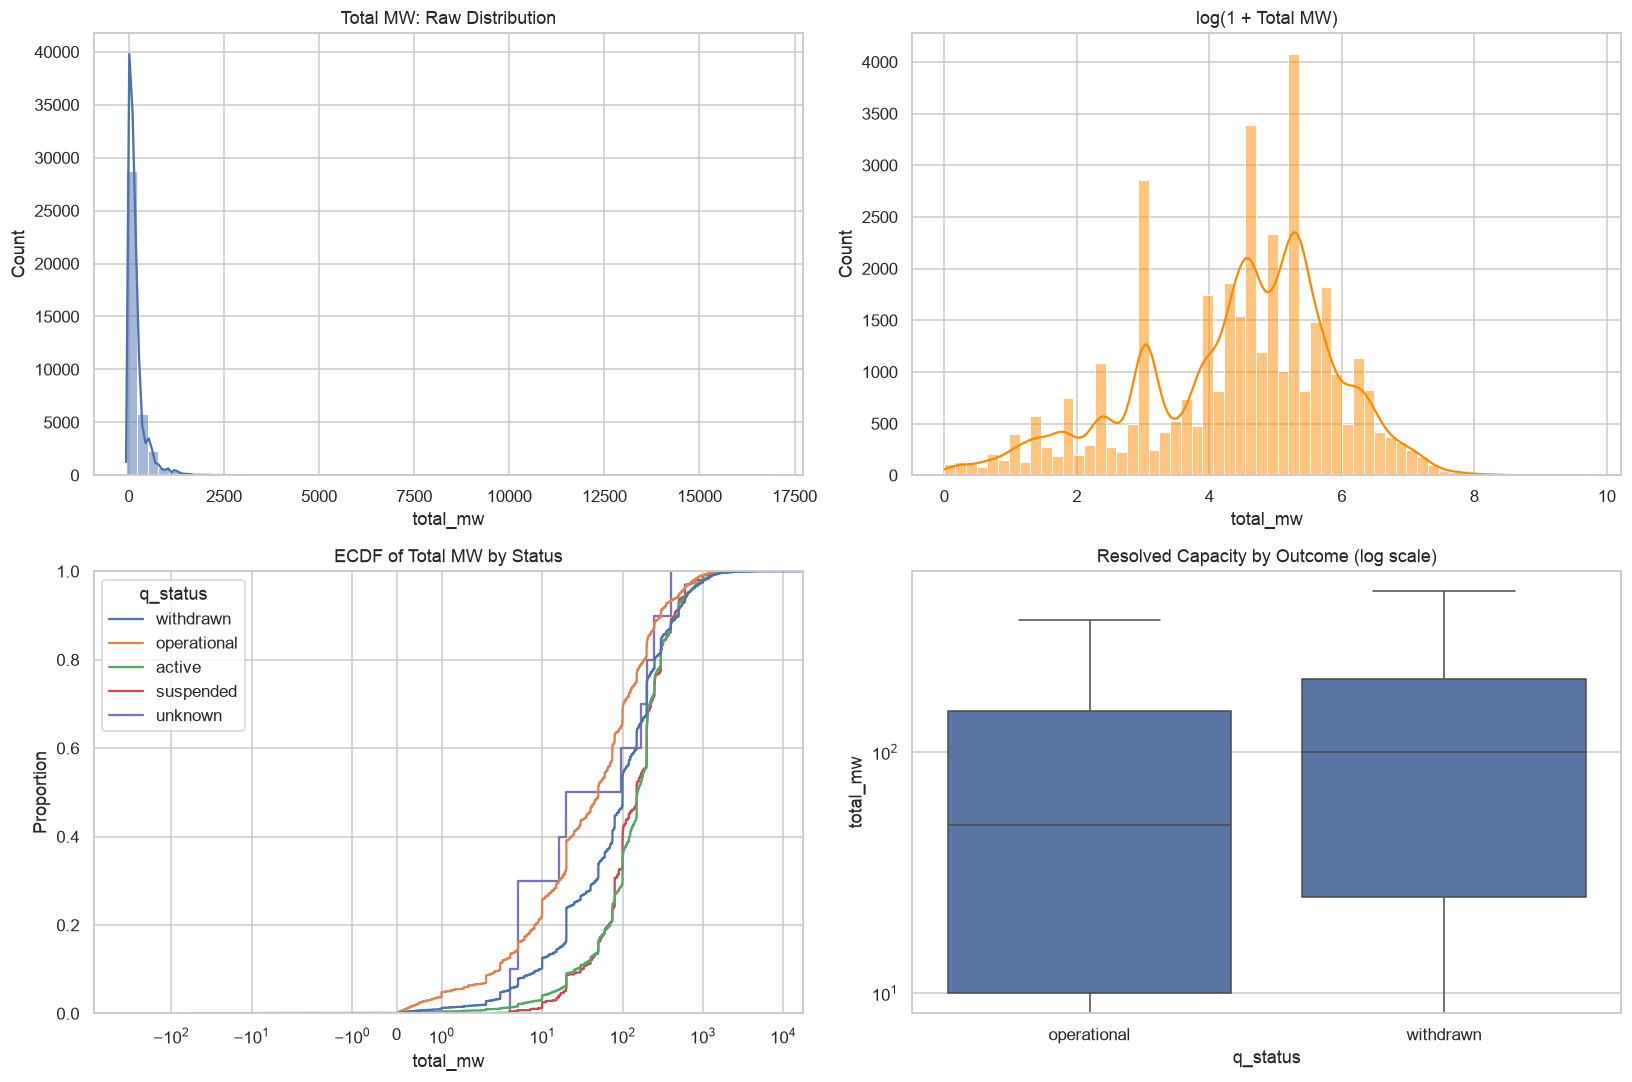

In [7]:
def distribution_diagnostics(series, name):
    x = pd.to_numeric(series, errors="coerce").dropna()
    positive = x[x > 0]
    result = {
        "feature": name,
        "n": len(x),
        "mean": x.mean(),
        "median": x.median(),
        "std": x.std(),
        "skew": stats.skew(x, nan_policy="omit") if len(x) > 2 else np.nan,
        "kurtosis": stats.kurtosis(x, nan_policy="omit") if len(x) > 3 else np.nan,
        "positive_n": len(positive),
    }
    return result

numeric_summary = pd.DataFrame([
    distribution_diagnostics(df["mw_1"], "mw_1"),
    distribution_diagnostics(df["total_mw"], "total_mw"),
])
display(numeric_summary.round(3))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df["total_mw"], bins=60, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Total MW: Raw Distribution")

positive_mw = df.loc[df["total_mw"] > 0, "total_mw"]
sns.histplot(np.log1p(positive_mw), bins=60, kde=True, ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("log(1 + Total MW)")

sns.ecdfplot(data=df, x="total_mw", hue="q_status", ax=axes[1, 0])
axes[1, 0].set_xscale("symlog")
axes[1, 0].set_title("ECDF of Total MW by Status")

sns.boxplot(data=resolved, x="q_status", y="total_mw",
            order=["operational", "withdrawn"], showfliers=False, ax=axes[1, 1])
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Resolved Capacity by Outcome (log scale)")
plt.tight_layout()
plt.show()

## 7. Technology, service, geography, and outcome

,count,operational_rate
type_1,,
Solar,13192,0.101956
Wind,5715,0.194576
Battery,3622,0.050248
Gas,3237,0.310164
Other,1605,0.326480
Hydro,457,0.509847
Coal,421,0.406176
Offshore Wind,195,0.015385
Nuclear,164,0.585366


,count,operational_rate
region,,
PJM,6418,0.185728
West,6240,0.154327
MISO,3778,0.136316
Southeast,3267,0.161922
CAISO,2435,0.096509
SPP,2145,0.139394
ERCOT,1771,0.346132
NYISO,1746,0.123139
ISO-NE,1210,0.188430


,count,operational_rate
service,,
NRIS,12875,0.154019
NaN,8028,0.228201
ERIS,3901,0.177647
NRIS/ERIS,3484,0.033295
Other,722,0.228532


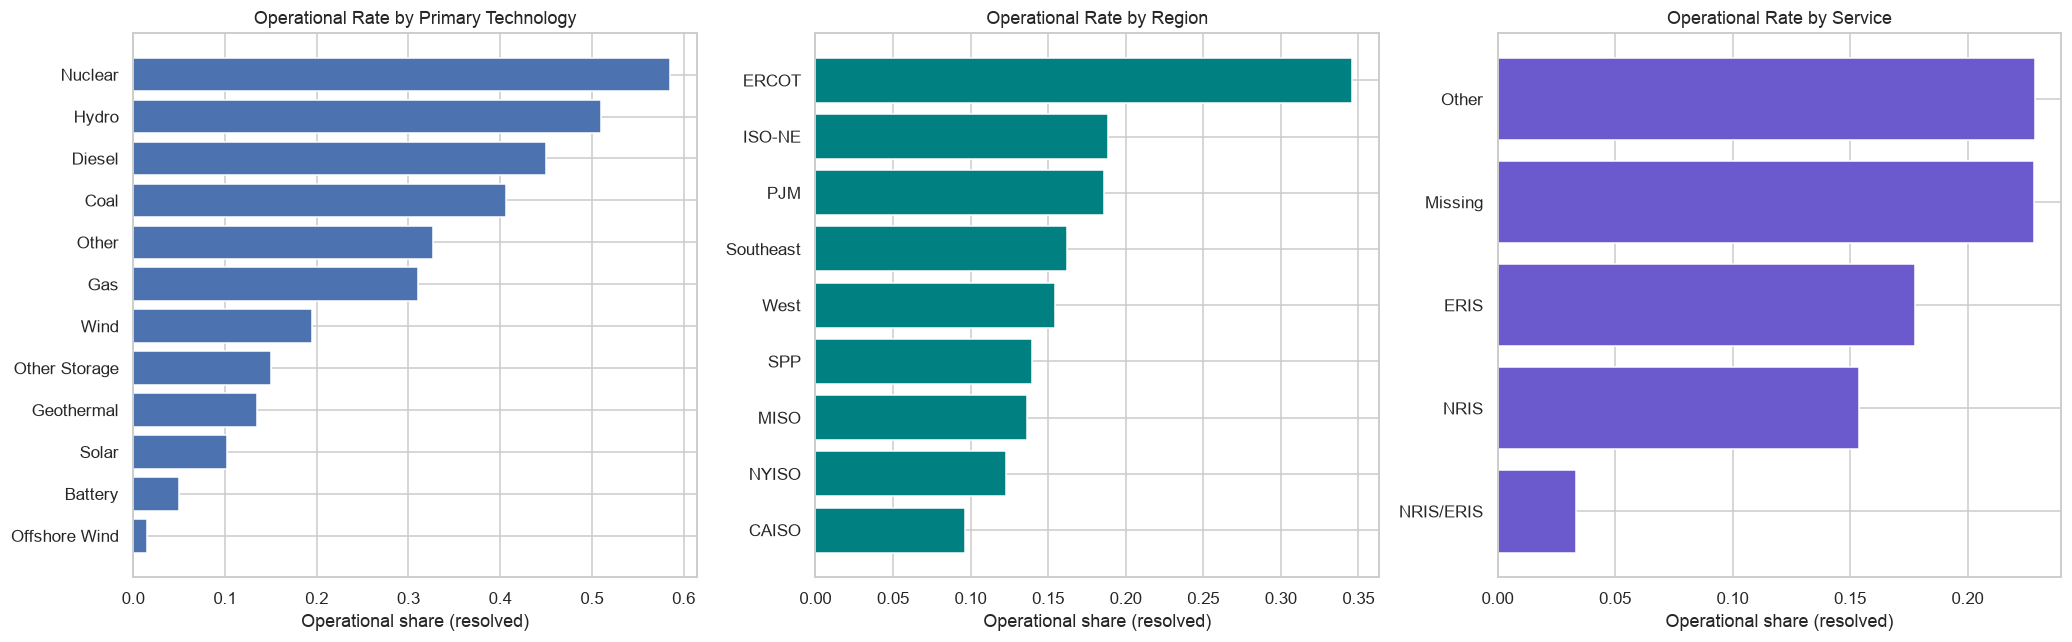

In [8]:
def rate_table(data, group_col, min_count=20):
    out = (
        data.groupby(group_col, dropna=False)["reached_operation"]
            .agg(["count", "mean"])
            .rename(columns={"mean": "operational_rate"})
    )
    return out[out["count"] >= min_count].sort_values("count", ascending=False)

type_rates = rate_table(resolved, "type_1")
region_rates = rate_table(resolved, "region")
service_rates = rate_table(resolved, "service")

display(type_rates.head(20))
display(region_rates)
display(service_rates)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
type_plot = type_rates.head(12).sort_values("operational_rate")
axes[0].barh(type_plot.index.astype(str), type_plot["operational_rate"])
axes[0].set_title("Operational Rate by Primary Technology")
axes[0].set_xlabel("Operational share (resolved)")

region_plot = region_rates.sort_values("operational_rate")
axes[1].barh(region_plot.index.astype(str), region_plot["operational_rate"], color="teal")
axes[1].set_title("Operational Rate by Region")
axes[1].set_xlabel("Operational share (resolved)")

service_plot = service_rates.sort_values("operational_rate")
service_labels = ["Missing" if pd.isna(value) else str(value)
                  for value in service_plot.index]
axes[2].barh(service_labels, service_plot["operational_rate"], color="slateblue")
axes[2].set_title("Operational Rate by Service")
axes[2].set_xlabel("Operational share (resolved)")
plt.tight_layout()
plt.show()

## 8. Queue cohorts and label maturity

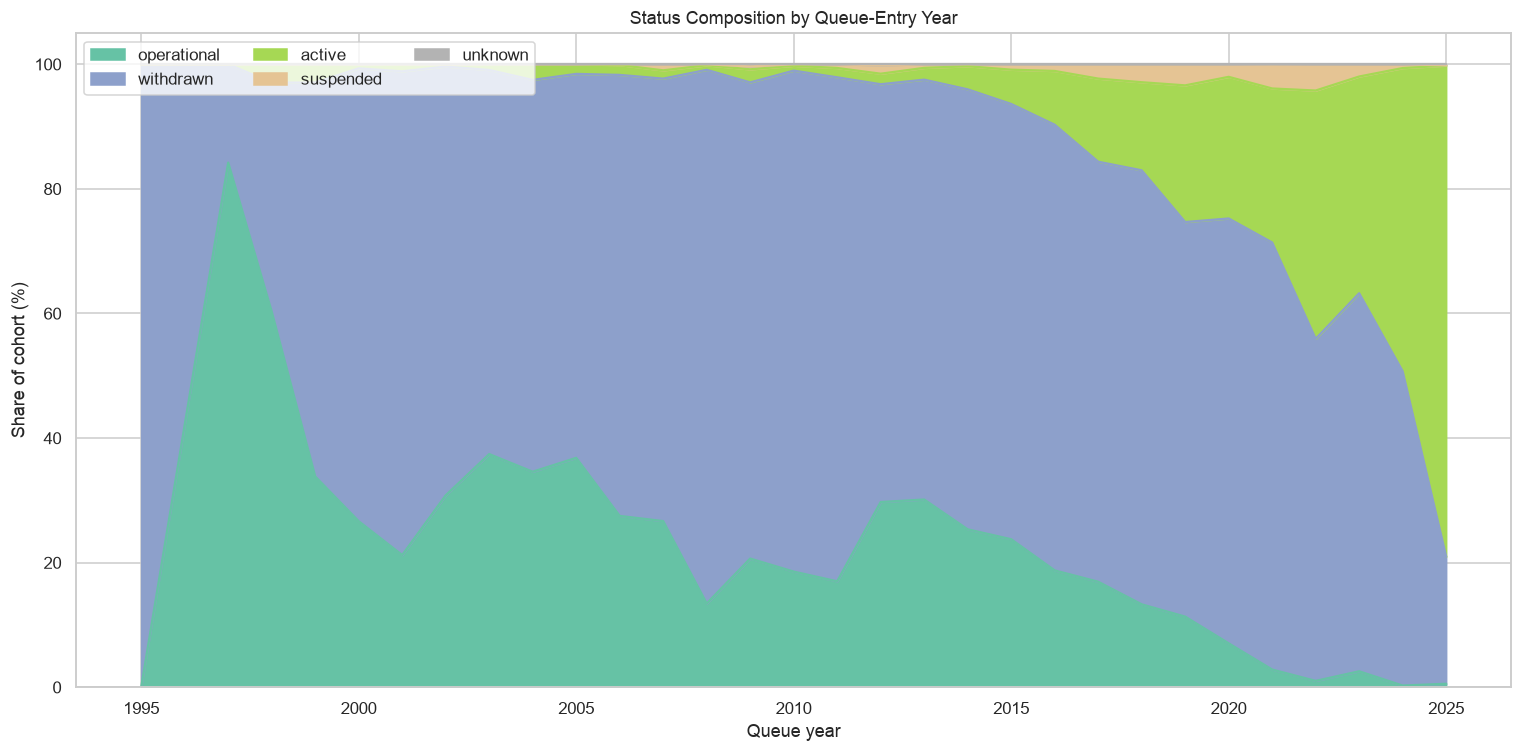

q_status,active,operational,suspended,unknown,withdrawn
queue_year,,,,,
2011.0,15,170,6,0,809
2012.0,10,176,8,1,397
2013.0,13,207,4,0,463
2014.0,35,239,3,0,666
2015.0,63,272,10,0,800
2016.0,144,313,18,0,1194
2017.0,249,316,43,0,1258
2018.0,289,272,59,0,1424
2019.0,511,264,79,0,1475


Recent cohorts contain many active projects; random splits would treat immature cohorts incorrectly.


In [9]:
cohort = pd.crosstab(df["queue_year"], df["q_status"], normalize="index") * 100
cohort = cohort.reindex(columns=[
    "operational", "withdrawn", "active", "suspended", "unknown"
], fill_value=0)

fig, ax = plt.subplots(figsize=(14, 7))
cohort.plot.area(stacked=True, ax=ax, colormap="Set2")
ax.set_title("Status Composition by Queue-Entry Year")
ax.set_ylabel("Share of cohort (%)")
ax.set_xlabel("Queue year")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

display(pd.crosstab(df["queue_year"], df["q_status"]).tail(15))
print("Recent cohorts contain many active projects; random splits would treat immature cohorts incorrectly.")

## 9. CAISO and California-focused assessment

,cohort,projects,operational,withdrawn,active
0,All Berkeley,38201,4789,24221,8513
1,CAISO region,2868,235,2200,432
2,CAISO + CA state,2645,219,2050,375


q_status,operational,withdrawn
type_1,,
Solar,132,1145
Wind,20,180


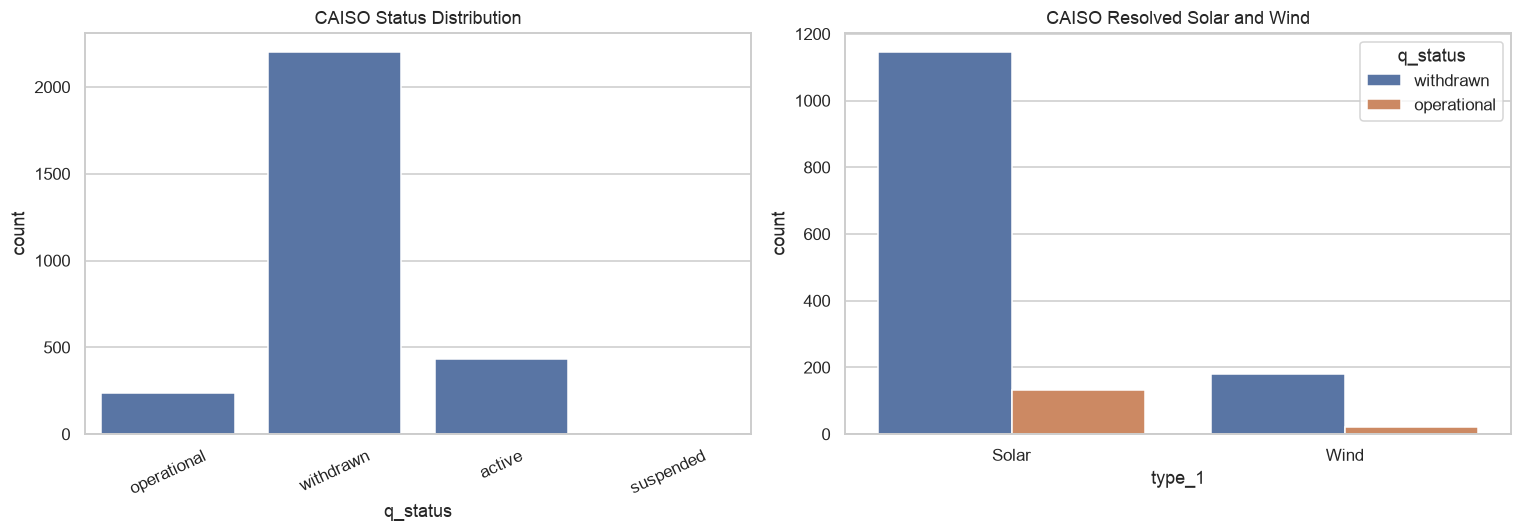

In [10]:
caiso = df[df["region"] == "CAISO"].copy()
caiso_ca = caiso[caiso["state"] == "CA"].copy()
caiso_resolved = caiso[caiso["q_status"].isin(["operational", "withdrawn"])].copy()
caiso_resolved["reached_operation"] = (
    caiso_resolved["q_status"] == "operational"
).astype(int)

summary = pd.DataFrame({
    "cohort": ["All Berkeley", "CAISO region", "CAISO + CA state"],
    "projects": [len(df), len(caiso), len(caiso_ca)],
    "operational": [
        (df["q_status"] == "operational").sum(),
        (caiso["q_status"] == "operational").sum(),
        (caiso_ca["q_status"] == "operational").sum(),
    ],
    "withdrawn": [
        (df["q_status"] == "withdrawn").sum(),
        (caiso["q_status"] == "withdrawn").sum(),
        (caiso_ca["q_status"] == "withdrawn").sum(),
    ],
    "active": [
        (df["q_status"] == "active").sum(),
        (caiso["q_status"] == "active").sum(),
        (caiso_ca["q_status"] == "active").sum(),
    ],
})
display(summary)

solar_wind = caiso_resolved[
    caiso_resolved["type_1"].isin(["Solar", "Wind"])
].copy()
tech_status = pd.crosstab(solar_wind["type_1"], solar_wind["q_status"])
display(tech_status)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=caiso, x="q_status",
              order=["operational", "withdrawn", "active", "suspended"], ax=axes[0])
axes[0].set_title("CAISO Status Distribution")
axes[0].tick_params(axis="x", rotation=25)

sns.countplot(data=solar_wind, x="type_1", hue="q_status", ax=axes[1])
axes[1].set_title("CAISO Resolved Solar and Wind")
plt.tight_layout()
plt.show()

## 10. Timing analysis and a second-model opportunity

,queue_to_operation_days,queue_to_withdrawal_days
count,3146.000000,15373.000000
mean,1361.380483,783.318611
std,1003.803827,729.045881
min,-8930.000000,-555.000000
25%,692.000000,242.000000
50%,1291.000000,595.000000
75%,1886.000000,1178.000000
max,6628.000000,8947.000000


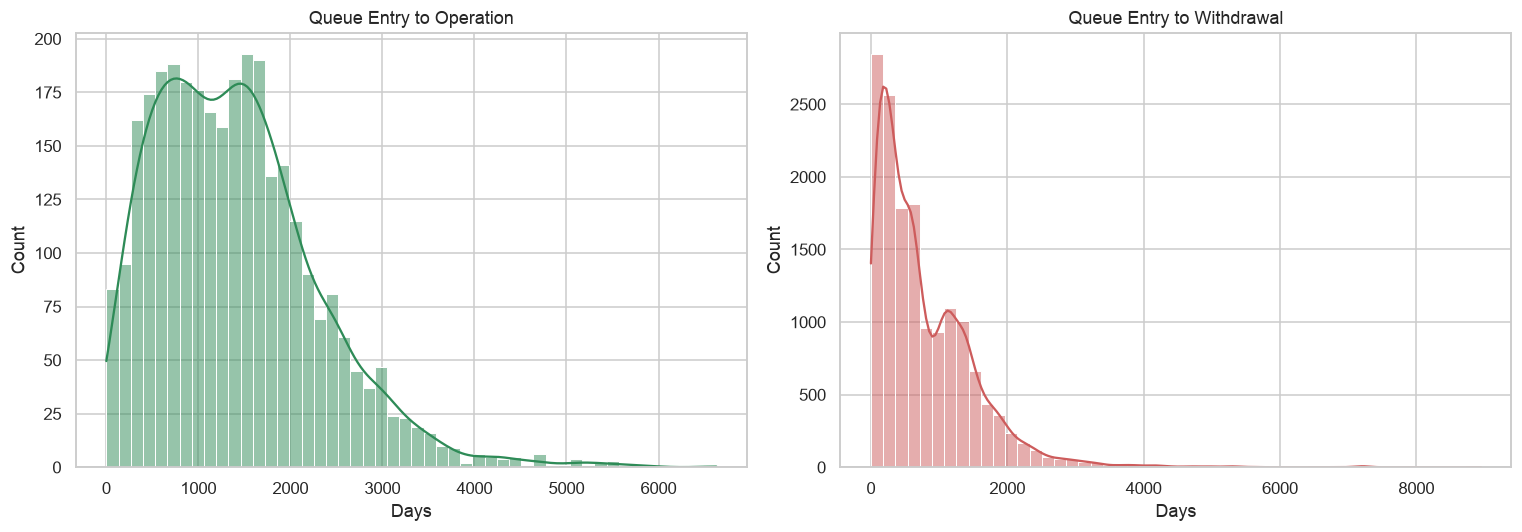

In [11]:
df["days_queue_to_operation"] = (df["on_date"] - df["q_date"]).dt.days
df["days_queue_to_withdrawal"] = (df["wd_date"] - df["q_date"]).dt.days

duration_summary = pd.DataFrame({
    "queue_to_operation_days": df.loc[df["q_status"] == "operational",
                                      "days_queue_to_operation"].describe(),
    "queue_to_withdrawal_days": df.loc[df["q_status"] == "withdrawn",
                                       "days_queue_to_withdrawal"].describe(),
})
display(duration_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
op_days = df.loc[
    (df["q_status"] == "operational") & (df["days_queue_to_operation"] >= 0),
    "days_queue_to_operation"
]
wd_days = df.loc[
    (df["q_status"] == "withdrawn") & (df["days_queue_to_withdrawal"] >= 0),
    "days_queue_to_withdrawal"
]
sns.histplot(op_days, bins=50, kde=True, ax=axes[0], color="seagreen")
axes[0].set_title("Queue Entry to Operation")
axes[0].set_xlabel("Days")
sns.histplot(wd_days, bins=50, kde=True, ax=axes[1], color="indianred")
axes[1].set_title("Queue Entry to Withdrawal")
axes[1].set_xlabel("Days")
plt.tight_layout()
plt.show()

## 11. What the data can and cannot explain

### It can support
- Associations between queue-entry attributes and eventual operation versus withdrawal.
- CAISO- and California-specific historical completion rates.
- Technology, size, service, region, and queue-vintage risk segmentation.
- Time-to-event modeling when active records are treated as right-censored.

### It cannot establish
- Formal “approval” or “rejection”: withdrawal may be voluntary, economic, procedural, or technical.
- Causal reasons for withdrawal without study-cost, upgrade-cost, financing, permitting, and grid-constraint evidence.
- The outcome of current active projects until those records mature.

Observed group differences are predictive associations, not causal explanations.

## 12. Feature policy for queue-entry ML

In [12]:
feature_policy = pd.DataFrame([
    ("q_date / q_year", "Use", "Known at queue entry; preserve temporal effects"),
    ("region, state, county", "Use", "Geographic and market context"),
    ("type_1/2/3, type_clean", "Use", "Technology and hybrid configuration"),
    ("mw_1/2/3, total_mw", "Use", "Requested project capacity"),
    ("service, project_type, cluster", "Use", "Application characteristics"),
    ("utility, entity, poi_name", "Conditional", "High cardinality; encode in train folds only"),
    ("project_name, developer", "Usually exclude", "Identifiers/high cardinality"),
    ("IA_phase_raw / IA_phase_clean", "Exclude at queue entry", "Latest phase is post-application and partly outcome-derived"),
    ("ia_date, wd_date, on_date", "Exclude", "Direct post-outcome leakage"),
    ("event durations", "Exclude as classifier inputs", "Computed using outcome dates"),
], columns=["feature_group", "policy", "reason"])
display(feature_policy)

,feature_group,policy,reason
0,q_date / q_year,Use,Known at queue entry; preserve temporal effects
1,"region, state, county",Use,Geographic and market context
2,"type_1/2/3, type_clean",Use,Technology and hybrid configuration
3,"mw_1/2/3, total_mw",Use,Requested project capacity
4,"service, project_type, cluster",Use,Application characteristics
5,"utility, entity, poi_name",Conditional,High cardinality; encode in train folds only
6,"project_name, developer",Usually exclude,Identifiers/high cardinality
7,IA_phase_raw / IA_phase_clean,Exclude at queue entry,Latest phase is post-application and partly ou...
8,"ia_date, wd_date, on_date",Exclude,Direct post-outcome leakage
9,event durations,Exclude as classifier inputs,Computed using outcome dates


## 13. Final ML assessment

### Recommended primary model
Train a calibrated binary classifier on **resolved `operational` versus `withdrawn` projects**, using only queue-entry features. Evaluate with temporal holdouts and CAISO/California subgroup metrics. Because the data are imbalanced, prioritize PR-AUC, class-specific recall/precision, Brier score, and calibration—not accuracy alone.

For the California solar MVP:
1. Use the Berkeley CAISO/California resolved cohort as the canonical labeled source.
2. Train on all suitable technologies with technology indicators, then report solar-specific performance; compare against a solar-only model only if sample size supports it.
3. Exclude all Cluster 15 IDs from model development before scoring those projects.

### Optional second model
Use competing-risks survival analysis to estimate time to either operation or withdrawal. Active projects are useful here as right-censored observations.

### Final wording
Report **“probability of eventually reaching operation before withdrawal”** and an estimated event-time range. Do not claim formal acceptance/rejection probability or causal reasons unsupported by the data.